<a href="https://colab.research.google.com/github/cowbow244/Data-Analysis-with-Open-Source/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_13%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13강 반정형 데이터 분석 : 게시판 글 데이터 활용

### 목표

방송통신대학교 학생 게시판의 글 제목을 수집하고 분석하여, 반정형 데이터의 수집부터 텍스트 분석까지 전체 과정을 실습

### 분석 프로세스 개요

1. 데이터 수집
  - selenium을 활용한 웹 페이지 접근
  - lxml을 이용한 HTML 파싱
  - 게시글 제목 추출

2. 텍스트 데이터 전처리
  - 정규식을 활용한 텍스트 정제
  - 형태소 분석을 통한 명사 추출

3. 키워드 분석
  - 단어 빈도 분석
  - 워드 클라우드 생성
  - 주요 키워드 추출

4. 텍스트 분류 및 시각화
  - LLM을 활용한 텍스트 분류
  - 분류 결과 시각화
  - 인사이트 도출


# 주의 : 런타임 GPU 로 설정 필요

In [23]:
# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업이므로 미리 실행!)
!pip install vllm==0.9.0 transformers==4.52.4
# 필요 시 세션 재시작

ERROR: Ignored the following yanked versions: 0.2.1
ERROR: Ignored the following versions that require a different python version: 0.10.0 Requires-Python <3.13,>=3.9; 0.10.1 Requires-Python <3.13,>=3.9; 0.10.1.1 Requires-Python <3.13,>=3.9; 0.8.4 Requires-Python <3.13,>=3.9; 0.8.5 Requires-Python <3.13,>=3.9; 0.8.5.post1 Requires-Python <3.13,>=3.9; 0.9.0 Requires-Python <3.13,>=3.9; 0.9.0.1 Requires-Python <3.13,>=3.9; 0.9.1 Requires-Python <3.13,>=3.9; 0.9.2 Requires-Python <3.13,>=3.9
ERROR: Could not find a version that satisfies the requirement vllm==0.9.0 (from versions: 0.0.1, 0.1.0, 0.1.1, 0.1.2, 0.1.3, 0.1.4, 0.1.5, 0.1.6, 0.1.7, 0.2.0, 0.2.1.post1, 0.2.2, 0.2.3, 0.2.4, 0.2.5, 0.2.6, 0.2.7, 0.3.0, 0.3.1, 0.3.3, 0.4.1, 0.4.2, 0.4.3, 0.5.0, 0.5.0.post1, 0.5.1, 0.5.2, 0.5.3, 0.5.3.post1, 0.5.4, 0.5.5, 0.6.0, 0.6.1, 0.6.1.post1, 0.6.1.post2, 0.6.2, 0.6.3, 0.6.3.post1, 0.6.4, 0.6.4.post1, 0.6.5, 0.6.6, 0.6.6.post1, 0.7.0, 0.7.1, 0.7.2, 0.7.3, 0.8.0, 0.8.1, 0.8.2, 0.8.3, 0.10.2, 0.1

In [21]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 70 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,221 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127719 files and

- 런타임 -> 세션 다시 시작

In [3]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 13-1 웹 스크래핑 라이브러리 설치

In [2]:
!pip install google-colab-selenium lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.8/511.8 kB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 77.3 MB/s eta 0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0


## 13-2 웹 스크래핑 함수 정의 및 실행

In [3]:
import google_colab_selenium as gs
from lxml import html

## URL로부터 페이지 내용 가져오기
def get_page(driver, url):
    # url 페이지로 이동
    driver.get(url)
    # 해당 페이지의 html을 page_content로 저장
    page_content = driver.page_source
    # page_content를 lxml의 html 객체로 변환하고 tree로 저장
    tree = html.fromstring(page_content)
    return tree

## HTML 트리에서 제목 추출
def extract_titles(tree):
    ## td-subject를 클래스로 가지는 td 태그 > a태그 > string > text() 을 xpath로 구하고 titles로 저장
    titles = tree.xpath('//td[@class="td-subject"]/a/strong/text()')
    return titles

## 제목 목록 출력
def print_titles(titles):
    for title in titles:
        print(title)

## Chrome 드라이버 초기화
driver = gs.Chrome()

## 컴퓨터과학과 게시판 첫번째 페이지 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
tree = get_page(driver, board_url)
titles = extract_titles(tree)
print_titles(titles)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)


## 13-3 다중 페이지 데이터 수집 및 데이터프레임 생성

In [6]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd

## 다음 페이지로 이동하고 tree 정보 반환
def move_to_next_page(driver):
    # _listNext 클래스를 기준으로 엘리먼트 선택
    next_page_link = driver.find_element(By.CLASS_NAME, "_listNext")
    if next_page_link and next_page_link.is_enabled():
        # 다음 페이지 버튼 클릭
        next_page_link.click()
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CLASS_NAME, "board-table"))
        )
        page_content = driver.page_source
        tree = html.fromstring(page_content)
        return tree
    else:
        return None

## 여러 페이지에서 게시물 제목 가져오기
def get_board_titles(url, pages, verbose=False):
    driver = gs.Chrome()
    board_titles = []
    for page in pages:
        if verbose:
          print(f"=== 페이지 {page} 처리중입니다. ===")
        if page == 1:
            # 13-2 에서 작성한 get_page 함수를 이용하여 현재 페이지 tree 구하기
            tree = get_page(driver, url)
        else:
            # 다음 페이지로 이동하고 해당 페이지 tree 구하기
            tree = move_to_next_page(driver)
        if tree is not None:
            titles = extract_titles(tree)
            board_titles.extend(titles)
            if verbose:
              print_titles(titles)
    driver.quit()  # Chrome 드라이버 종료
    return board_titles

## 컴퓨터과학과 게시판 1 페이지 ~ 10 페이지의 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=True)
## 컴퓨터과학과 제목 데이터프레임 생성
cs_df = pd.DataFrame(data = {'제목': board_titles})

<IPython.core.display.Javascript object>

=== 페이지 1 처리중입니다. ===
연극치료 임상실습 참여자 모집
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
=== 페이지 2 처리중입니다. ===
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
방송대 모든 학과 과제&기출 창고
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
극예술연구회   회원모집
 ★ 극예술연구회 ★ 연극동아리 49기 신입 회원 모집
2학기 학습 자료 및 기출문제 안내[방송대 방모창] 
🚨🚨방통대생들 다 모였다! 국내 최대 온라인 학생모임 ‘방송대인’🚨🚨
🚨🚨방통대생들 다 모였다! 국내 최대 온라인 학생모임 ‘방송대인’🚨🚨
=== 페이지 3 처리중입니다. ===
🔔 "방송대 공지사항 알리미"가 새로 생겼습니다!!! 🔔카카오톡 단톡
※ 연극동아리(극예술연구회) 49기 신입단원( 배우 및 스텝)모집 ※
연극
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
🔔평점 4.5점 만점자 전화 인터뷰 들으러 가기🔔치킨 기프티콘🔔네이버 대표카페🔔참고
'학습 품앗이 3·3·3 캠페인’으로 서로 채워주는 방송대 
📚 방통신(방송대) 기출문제·요점정리·교재장터 한곳에! 대표 커뮤니티
극예술연구회   회원모집
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
★ 극예술연구회 ★ 연극동아리 49기 신입 회원 모집
=== 페이지 4 처리중입니다. 

# 2. 텍스트 데이터 전처리

## 13-4 정규식을 활용한 텍스트 정제

In [7]:
import re

## 텍스트 정제 함수
def clean_text(text):
    if isinstance(text, str):
       # 특수 문자 제거 regex (영어 소문자, 영어 대문자, 숫자, 한글, 공백글자만 허용)
       text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text)
       # HTML 태그 제거 regex
       text = re.sub(r'<[^>]*>', '', text)
       # 소문자로 변환 python 함수
       text = text.lower()
       return text
    else:
        return ""

## 데이터프레임 정제 함수
def clean_df(df):
  if not df.empty:
      df['정제된 제목'] = df['제목'].apply(clean_text)

## cs_df에 정제 함수 적용
clean_df(cs_df)
cs_df

,제목,정제된 제목
0,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집
1,"<<영어연극회 ""끼"" 47회 정기공연 무료 초대 >>",영어연극회 끼 47회 정기공연 무료 초대
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방
3,웹 소설 '연극치료사',웹 소설 연극치료사
4,"과제물, 학습자료 가기",과제물 학습자료 가기
...,...,...
95,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트
96,"2학기 출발, 과제&기출문제 맛보기",2학기 출발 과제기출문제 맛보기
97,📢 [그로스로그] 컴퓨터과학과 개발 커뮤니티 그로스로그에서 6기 얼리버드 모집합니다!,그로스로그 컴퓨터과학과 개발 커뮤니티 그로스로그에서 6기 얼리버드 모집합니다
98,2026학년도 2학기 각종 평가 일정 안내,2026학년도 2학기 각종 평가 일정 안내


## 13-5 형태소 분석기 설치 및 실행 예시

In [8]:
## Kiwi 형태소 분석기 설치
!pip install kiwipiepy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 11.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 110.5 MB/s eta 0:00:00
  Created wheel for kiwipiepy_model: filename=kiwipiepy_model-0.24.0-py3-none-any.whl size=87973829 sha256=79475827c766a642f74047d5366d529d4cfb1427ea179d9abb10dd4ce6cc9d87
  Stored in directory: /root/.cache/pip/wheels/1e/08/d4/4ff00b71c6b738e5308a0867385c986a743e5307c5206da985
Successfully built kiwipiepy_model


In [9]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')

## 문장 형태소 분석 결과 출력
kiwi.analyze('안녕하세요 저는 방송대 학생입니다.')[0][0]

[Token(form='안녕', tag='NNG', start=0, len=2),
 Token(form='하', tag='XSA', start=2, len=1),
 Token(form='세요', tag='EF', start=3, len=2),
 Token(form='저', tag='NP', start=6, len=1),
 Token(form='는', tag='JX', start=7, len=1),
 Token(form='방송대', tag='NNP', start=9, len=3),
 Token(form='학생', tag='NNG', start=13, len=2),
 Token(form='이', tag='VCP', start=15, len=1),
 Token(form='ᆸ니다', tag='EF', start=15, len=3),
 Token(form='.', tag='SF', start=18, len=1)]

## 13-6 형태소 분석을 통한 품사 분리

In [10]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')
kiwi.add_user_word('방통대', 'NNP')

## 텍스트 형태소 분석 함수
def analyze_morphemes(text):
    if isinstance(text, str):
       result = kiwi.analyze(text)

       morphemes = []
       for token in result[0][0]:
            ## 형태소(form)와 품사(tag) 정보를 튜플로 morphemes에 추가
            morphemes.append((token.form, token.tag))

       return morphemes
    else:
        return []

## 데이터프레임에 형태소 분석 적용 함수
def pos_df(df):
  if not df.empty:
      # `정제된 제목` 칼럼의 값에 analyze_morphemes 함수를 적용하고 결과를 `행태소 분석 결과` 칼럼에 저장
      df['형태소 분석 결과'] = df['정제된 제목'].apply(analyze_morphemes)


## 형태소 분석 적용
pos_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과
0,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)..."
1,"<<영어연극회 ""끼"" 47회 정기공연 무료 초대 >>",영어연극회 끼 47회 정기공연 무료 초대,"[(영어, NNP), (연극, NNG), (회, NNG), (끼, NNG), (47..."
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)..."
3,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]"
4,"과제물, 학습자료 가기",과제물 학습자료 가기,"[(과제물, NNG), (학습, NNG), (자료, NNG), (가, VV), (기..."
...,...,...,...
95,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트,"[(2026, SN), (방통대, NNP), (과제물, NNG), (작성, NNG)..."
96,"2학기 출발, 과제&기출문제 맛보기",2학기 출발 과제기출문제 맛보기,"[(2, SN), (학기, NNG), (출발, NNG), (과제, NNG), (기출..."
97,📢 [그로스로그] 컴퓨터과학과 개발 커뮤니티 그로스로그에서 6기 얼리버드 모집합니다!,그로스로그 컴퓨터과학과 개발 커뮤니티 그로스로그에서 6기 얼리버드 모집합니다,"[(그, MM), (로스, NNG), (로그, NNG), (컴퓨터, NNG), (과..."
98,2026학년도 2학기 각종 평가 일정 안내,2026학년도 2학기 각종 평가 일정 안내,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (..."


## 13-7 명사 추출

In [11]:
## 형태소 분석 결과에서 명사 추출
def extract_nouns(morphemes):
  # 형태소가 NNG (일반명사), NNP (고유명사) 인 word를 nouns에 저장
  nouns = [word for word, tag in morphemes if tag in ['NNG', 'NNP']]
  return nouns

## 데이터프레임에 명사 추출 적용
def noun_df(df):
  if not df.empty:
      df['명사'] = df['형태소 분석 결과'].apply(extract_nouns)

## 명사 추출 적용
noun_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과,명사
0,연극치료 임상실습 참여자 모집,연극치료 임상실습 참여자 모집,"[(연극치료, NNP), (임상, NNG), (실습, NNG), (참여자, NNG)...","[연극치료, 임상, 실습, 참여자, 모집]"
1,"<<영어연극회 ""끼"" 47회 정기공연 무료 초대 >>",영어연극회 끼 47회 정기공연 무료 초대,"[(영어, NNP), (연극, NNG), (회, NNG), (끼, NNG), (47...","[영어, 연극, 회, 끼, 정기, 공연, 무료, 초대]"
2,🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방,크로바 네이버 카페 크로바 기출문제 카페 크로바 학사공지 전용 단톡방,"[(크로바, NNP), (네이버, NNP), (카페, NNG), (크로바, NNG)...","[크로바, 네이버, 카페, 크로바, 기출, 문제, 카페, 크로바, 학사, 공지, 전..."
3,웹 소설 '연극치료사',웹 소설 연극치료사,"[(웹, NNG), (소설, NNG), (연극, NNG), (치료사, NNG)]","[웹, 소설, 연극, 치료사]"
4,"과제물, 학습자료 가기",과제물 학습자료 가기,"[(과제물, NNG), (학습, NNG), (자료, NNG), (가, VV), (기...","[과제물, 학습, 자료]"
...,...,...,...,...
95,[2026 방통대] 과제물 작성법 & 감점 방지 제출 체크리스트,2026 방통대 과제물 작성법 감점 방지 제출 체크리스트,"[(2026, SN), (방통대, NNP), (과제물, NNG), (작성, NNG)...","[방통대, 과제물, 작성, 법, 감점, 방지, 제출, 체크, 리스트]"
96,"2학기 출발, 과제&기출문제 맛보기",2학기 출발 과제기출문제 맛보기,"[(2, SN), (학기, NNG), (출발, NNG), (과제, NNG), (기출...","[학기, 출발, 과제, 기출, 문제]"
97,📢 [그로스로그] 컴퓨터과학과 개발 커뮤니티 그로스로그에서 6기 얼리버드 모집합니다!,그로스로그 컴퓨터과학과 개발 커뮤니티 그로스로그에서 6기 얼리버드 모집합니다,"[(그, MM), (로스, NNG), (로그, NNG), (컴퓨터, NNG), (과...","[로스, 로그, 컴퓨터, 과학, 개발, 커뮤니티, 그로스로그, 기, 얼리버드, 모집]"
98,2026학년도 2학기 각종 평가 일정 안내,2026학년도 2학기 각종 평가 일정 안내,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (...","[학년도, 학기, 각종, 평가, 일정, 안내]"


## 13-8 데이터 전처리 통합 함수 정의

In [12]:
## 데이터프레임 전처리 통합 함수
def preprocessing_df(df):
  clean_df(df) ## 텍스트 정제 적용
  pos_df(df) ## 형태소 분석 적용
  noun_df(df) ## 명사 추출 적용

# 3. 키워드 분석

## 13-9 단어 빈도 계산

In [19]:
from collections import Counter

## 데이터프레임에서 단어 빈도 계산
def get_word_count(df):
    if not df.empty:
        # 모든 명사의 리스트를 구함
        all_nouns = df['명사'].sum()
        # 모든 명사들에 대한 Counter 객체(빈도 정보) 를 반환
        return Counter(all_nouns)

## cs_df의 단어 빈도 계산
word_count = get_word_count(cs_df)
print("단어 빈도:")
## 상위 30개 단어(most_common)의 빈도 출력. most_common 빈도수가 높은 순으로 정렬
for word, freq in word_count.most_common(30):
    print(f"{word}: {freq}")

단어 빈도:
모집: 44
연극: 33
회원: 27
동아리: 26
신입: 26
기: 19
방송대: 16
카페: 13
네이버: 12
기출: 12
문제: 12
극예술: 12
연구회: 12
대표: 12
참고: 11
극예술연구회: 10
요점: 9
정리: 9
웹: 8
소설: 8
치료사: 8
전통: 8
교재: 8
장터: 8
온라인: 7
그로스로그: 7
학점: 7
비서: 7
방통대: 6
통신: 6


## 13-10 워드클라우드 생성 및 시각화

In [15]:
## WordCloud 라이브러리 설치
!pip install wordcloud

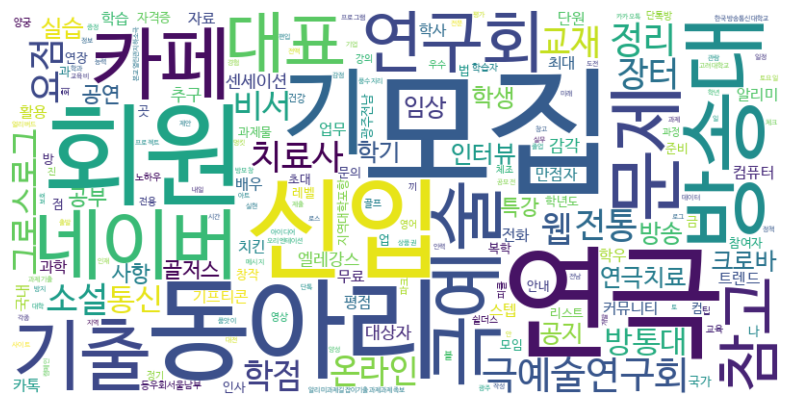

In [22]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 단어 빈도를 바탕으로 워드클라우드 생성 및 표시
def plot_wordcloud(word_count):
    ## 워드 클라우드 생성
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count)# word_count의 빈도 정보를 이용하여 생성

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear') ## 이미지 표시
    plt.axis("off") ## 축 비활성화
    plt.show() ## 그래프 표시

## cs_df에서 단어 빈도 계산
word_count = get_word_count(cs_df)
## 워드클라우드 생성 및 표시
plot_wordcloud(word_count)

## 13-11 다른 학과의 워드 클라우드 생성

<IPython.core.display.Javascript object>

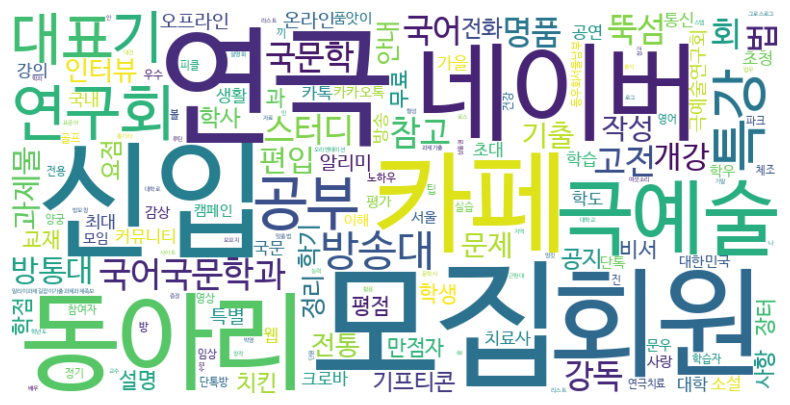

In [24]:
board_name = '국어국문학과'
board_url = 'https://korean.knou.ac.kr/korean/5323/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
ko_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(ko_df)
word_count = get_word_count(ko_df)
plot_wordcloud(word_count)

In [ ]:
board_name = '법학과'
board_url = 'https://law.knou.ac.kr/law/5176/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
law_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(law_df)
word_count = get_word_count(law_df)
plot_wordcloud(word_count)

# 4. 텍스트 분류 및 시각화

## 13-12 VLLM 라이브러리 설치 및 LLM 모델 로드

주의
- 런타임 유형 : GPU
- 라이브러리 설치 및 모델 다운로드에 수 분(>6분)의 시간이 소요됩니다.


In [26]:
from vllm import LLM

## LLM 모델 로드 및 설정
#LLM : 웹상에 공개되어 있는 LLM들을 가져와서
#gpu상에 올려서 사용할 수 있게 해주는 라이브러리
llm = LLM(
    model="LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct",
    tensor_parallel_size=1,
    dtype="half",
    gpu_memory_utilization=0.9,
    max_model_len=32000
)

ModuleNotFoundError: No module named 'vllm'

## 13-13 LLM 샘플링 파라미터 설정 및 프롬프트 생성

In [28]:
from vllm import SamplingParams ## SamplingParams 클래스 임포트

## 샘플링 파라미터 설정
sampling_params = SamplingParams(
    temperature=0.3, ## 생성 텍스트의 다양성 조절
    top_p=1.0, ## top_p 누적 확률 내에서 토큰 샘플링
    max_tokens=512, ## 생성될 최대 토큰 수
    frequency_penalty=0.5 ## 자주 나타나는 토큰에 대한 패널티
)

def format_prompt(user_input: str) -> str:
    ## 프롬프트 형식화 함수
    messages = [
        # 시스템 메시지 추가. 시스템 메시지는 모델마다 고정이 되어 있다.
        # 사용자 메시지 추가
        {"role":"system", "content":"You are EXAONE model from LG AI Research, a helpful asssistance"}
        {"role":"user", "content": user_input}
    ]
    return messages

## 프롬프트 생성
prompt = format_prompt("대한민국의 수도는 어디인가요? 수도에 여행하러간다면 어떤 즐길거리가 있을까요?")

## LLM을 사용하여 텍스트 생성
# chat 함수를 이용 (프롬프트와 샘플링 파라미터)
outputs = llm.chat(prompt, sampling_params)

## 생성된 텍스트 출력
print("\n생성된 텍스트:", outputs[0].outputs[0].text)

SyntaxError: expression expected after dictionary key and ':' (761311615.py, line 17)

## 13-14 LLM 기반 분류 프롬프트 및 함수 정의

In [ ]:
## 분류 프롬프트 형식화 함수
def format_classifier_prompt(board_title, title) -> str:
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."},
        {"role": "user", "content": """주어진 글의 제목을 분류하는 AI 모델입니다.
분류 클래스는 학사/전공, 학생활동, 외부정보로 나뉘어집니다.
- 학사/전공: 교재, 과제, 시험 등 학업 및 전공 관련 내용
- 학생활동: 동아리, 스터디, 모임 등 학생들의 자발적 활동
- 외부정보: 취업, 공모전, 행사 등 외부 정보"""},
        {"role": "user", "content": """예시)
전공명: 컴퓨터학과, 제목: 프로그래밍 과제 질문 -> 학사/전공
전공명: 컴퓨터학과, 제목: 알고리즘 스터디 모집 -> 학생활동
전공명: 컴퓨터학과, 제목: IT 취업 박람회 -> 외부정보"""},
        {"role": "user", "content": f"전공명: {board_title}\n제목: {title}"}
    ]
    return messages

## 분류 수행 함수
def classify(major, title):
    prompt = format_classifier_prompt(major, title) ## 분류 프롬프트 생성
    outputs = llm.chat([prompt], sampling_params) ## LLM으로 분류 실행
    return outputs[0].outputs[0].text ## 분류 결과 텍스트 반환

In [ ]:
classify('컴퓨터학과', '딥러닝 개발 중에 질문 있습니다.')

In [ ]:
classify('컴퓨터학과', '연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!')

## 13-15 분류 결과 파싱 함수 정의

In [ ]:
def get_class(analysis_result):
    ## 분석 결과에서 분류 클래스 추출
    classes = ['학사/전공', '학생활동', '외부정보', '기타']
    classes_index = [analysis_result.find(cls) for cls in classes]

    min_index = float('inf')
    min_class = '기타'

    for i in range(len(classes)):
        current_index = classes_index[i]
        if current_index != -1 and current_index < min_index:
            min_index = current_index
            min_class = classes[i]

    return min_class

In [ ]:
## 컴퓨터과학과 제목 분류 헬퍼 함수 정의
def classify_cs(title):
  return classify('컴퓨터과학과', title)

## '제목' 컬럼에 분류 함수 적용하여 분석 결과 저장
cs_df['class_analysis'] = cs_df['제목'].apply(classify_cs)
## 분석 결과에서 최종 분류 클래스 추출하여 저장
cs_df['class'] = cs_df['class_analysis'].apply(get_class)

## 13-17 분류 결과 시각화

In [ ]:
def plot_class(df):
  ## 분류 클래스별 개수 계산 및 순서 재정렬
  class_counts = df['class'].value_counts().reindex(['학사/전공', '학생활동', '외부정보'])

  plt.figure(figsize=(8, 6)) ## 그래프 크기 설정
  plt.pie(class_counts,
          labels=class_counts.index,
          autopct='%.1f%%', ## 퍼센트 표시 형식
          startangle=90, ## 시작 각도 설정
          )

  plt.title('Class Distribution') ## 그래프 제목 설정
  plt.axis('equal') ## 원형 비율 유지
  plt.show() ## 그래프 표시

plot_class(cs_df)

## 13-18 다른 학과의 분류 결과 시각화

In [ ]:
def classify_ko(title):
  return classify('국어국문학과', title)

ko_df['class_analysis'] = ko_df['제목'].apply(classify_ko)
ko_df['class'] = ko_df['class_analysis'].apply(get_class)

def classify_law(title):
  return classify('법학과', title)

law_df['class_analysis'] = law_df['제목'].apply(classify_law)
law_df['class'] = law_df['class_analysis'].apply(get_class)

In [ ]:
plot_class(ko_df)

In [ ]:
plot_class(law_df)